# Model lineal de predicció demogràfica · Barcelona 1997–2026

+ **Durada estimada:** 2 hores
+ **Prerequisit:** exercici1.ipynb
+ **Eines:** Python 3 · pandas · numpy · matplotlib

---

## Pregunta de recerca

A partir de les dades de la gràfica *Distribució de la població per lloc de
naixement · 1997–2026*, construeix un model lineal **implementat des de zero,
amb gradient descendent**, que permeti respondre:

> **Si no canvien les tendències, quan superarà la població nascuda a la «Resta
> del món» la suma de la població nascuda a Barcelona, la Resta de Catalunya i
> la Resta d'Espanya?**

Recordatori dels grups del gràfic (`LLOC_NAIX`):

| Codi | Descripció |
|------|------------|
| 1 | Barcelona ciutat |
| 2 | Resta de Catalunya |
| 3 | Resta d'Espanya |
| 4 | Resta de la Unió Europea |
| 5 | Resta del món |
| 6 | No consta |

> **Nota:** Les cel·les marcades amb 🔧 contenen codi que has d'escriure o completar.
> Les marcades amb ✅ ja estan resoltes i serveixen de guia.

## Configuració inicial

In [1]:
# ✅
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

BASE          = "./data"
PATH_POBLACIO = os.path.join(BASE, "poblacio_lloc_naix")
PATH_DIMS     = os.path.join(BASE, "pad_dimensions.csv")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})
print("\u2713 Configuraci\u00f3 carregada")

✓ Configuració carregada


In [2]:
# ✅ Càrrega de tota la sèrie temporal
def netejar_poblacio(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")
    df = df[df["LLOC_NAIX"].isin(range(1, 7))].copy()
    df["Any"] = pd.to_datetime(df["Data_Referencia"]).dt.year
    return df

fitxers  = sorted(glob.glob(os.path.join(PATH_POBLACIO, "*.csv")))
df_serie = pd.concat([netejar_poblacio(f) for f in fitxers], ignore_index=True)

serie_anual = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Total"})
)
print(f"\u2713 {df_serie['Any'].nunique()} anys carregats "
      f"({df_serie['Any'].min()}\u2013{df_serie['Any'].max()})")

✓ 30 anys carregats (1997–2026)


---
## Part 1 — Dos grups de comparació

| Grup | Codis | Significat |
|------|-------|------------|
| **local** | 1, 2, 3 | Nascuts a Barcelona, Catalunya o Espanya |
| **exterior** | 4, 5 | Nascuts fora d'Espanya (UE, resta del món) |

Calcula per a cada any la població total de cada grup i la seva diferència
(`local − exterior`). Quan la diferència arribi a zero, els dos grups s'hauran
igualat.

In [3]:
# 🔧 Crea df_comparacio amb columnes: Any | local | exterior | diferencia
df_comparacio = (
    serie_anual[serie_anual["LLOC_NAIX"].isin([1, 2, 3, 4, 5])]
    .assign(Grup=lambda d: np.where(d["LLOC_NAIX"].isin([1, 2, 3]), "local", "exterior"))
    .groupby(["Any", "Grup"], as_index=False)["Total"]
    .sum()
    .pivot(index="Any", columns="Grup", values="Total")
    .reset_index()
)
df_comparacio.columns.name = None
df_comparacio["diferencia"] = df_comparacio["local"] - df_comparacio["exterior"]
df_comparacio = df_comparacio[["Any", "local", "exterior", "diferencia"]]

print(df_comparacio.tail(5).to_string(index=False))


 Any     local  exterior  diferencia
2022 1158323.0  481155.0    677168.0
2023 1141369.0  518523.0    622846.0
2024 1129845.0  572382.0    557463.0
2025 1119537.0  611951.0    507586.0
2026 1102515.0  626889.0    475626.0


---
## Part 2 — Visualització de les tendències

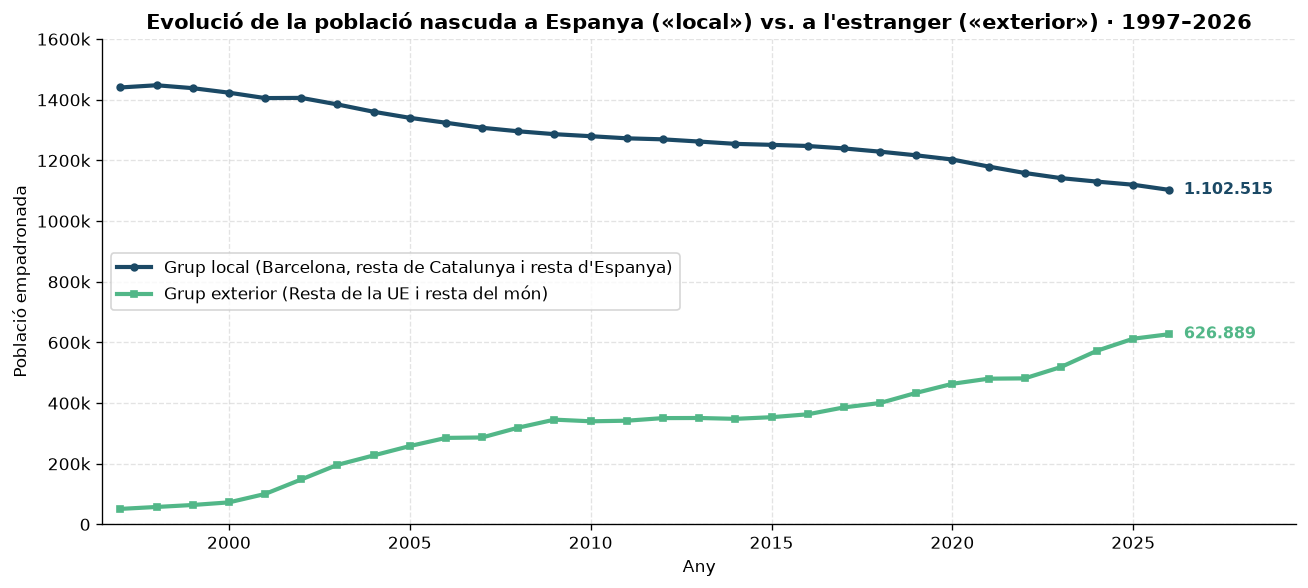

In [4]:
# 🔧 Gràfic de 2 línies: grup "local" i grup "exterior" 1997–2026
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    df_comparacio["Any"],
    df_comparacio["local"],
    color="#1b4965",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Grup local (Barcelona, resta de Catalunya i resta d'Espanya)",
)
ax.plot(
    df_comparacio["Any"],
    df_comparacio["exterior"],
    color="#52b788",
    linewidth=2.5,
    marker="s",
    markersize=4,
    label="Grup exterior (Resta de la UE i resta del món)",
)

val_local_2026 = int(df_comparacio.loc[df_comparacio["Any"] == 2026, "local"].values[0])
val_ext_2026 = int(df_comparacio.loc[df_comparacio["Any"] == 2026, "exterior"].values[0])

ax.annotate(
    f"{val_local_2026:,}".replace(",", "."),
    xy=(2026, val_local_2026),
    xytext=(2026.4, val_local_2026),
    va="center",
    fontsize=9.5,
    fontweight="bold",
    color="#1b4965",
)
ax.annotate(
    f"{val_ext_2026:,}".replace(",", "."),
    xy=(2026, val_ext_2026),
    xytext=(2026.4, val_ext_2026),
    va="center",
    fontsize=9.5,
    fontweight="bold",
    color="#52b788",
)

ax.set_title("Evolució de la població nascuda a Espanya («local») vs. a l'estranger («exterior») · 1997–2026", fontsize=12.5, fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Població empadronada")
ax.set_xlim(1996.5, 2029.5)
ax.set_ylim(0, 1600000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x/1000)}k" if x > 0 else "0"))
ax.legend(loc="center left", frameon=True)

plt.tight_layout()
plt.show()


---
## Part 3 — Regressió lineal i gradient descendent: conceptes

### El model

Volem ajustar una recta que descrigui com evoluciona la diferència
(`local − exterior`) al llarg del temps:

$$\hat{y} = m \cdot t + b$$

on $t$ és l'any, $\hat{y}$ és la diferència predita, $m$ és el
**pendent** i $b$ el **terme independent**.

### La funció de cost (MSE)

Per mesurar com de bé s'ajusta la recta usem l'**error quadràtic
mitjà** (*mean squared error*):

$$J(m, b) = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2
          = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - (m \cdot t_i + b)\right)^2$$

L'objectiu és trobar els valors de $m$ i $b$ que **minimitzen** $J$.

### Gradient descendent

El **gradient descendent** actualitza $m$ i $b$ iterativament en la
direcció que redueix el cost:

$$m \leftarrow m - \alpha \cdot \frac{\partial J}{\partial m}
\qquad
b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}$$

on $\alpha$ és la **taxa d'aprenentatge** (*learning rate*). 

Derivant $J$:

$$\frac{\partial J}{\partial m} = \frac{-2}{n}
  \sum_{i=1}^{n} t_i \cdot \left(y_i - (m \cdot t_i + b)\right)$$

$$\frac{\partial J}{\partial b} = \frac{-2}{n}
  \sum_{i=1}^{n} \left(y_i - (m \cdot t_i + b)\right)$$

### Per què normalitzar les dades?

Els anys $t$ van de 1997 a 2026 (valors grans) i les diferències $d$ de
població son de l'ordre de centenars de milers. Quan les escales
dels inputs i outputs son molt diferents, els gradients tenen
magnituds molt dispars i el descens és lent o inestable.

**Solució: estandardització** (*z-score*):

$$t_{\text{norm}} = \frac{t - \mu_t}{\sigma_t}
\qquad
d_{\text{norm}} = \frac{d - \mu_d}{\sigma_d}$$

Amb dades estandarditzades, una taxa d'aprenentatge $\alpha \in [0.01, 0.5]$ sol funcionar bé.

---
## Part 4 — Implementació del gradient descendent

Implementa el gradient descendent en quatre passos: normalització,
funció de cost, gradients i bucle d'entrenament.

In [5]:
# 🔧 4.1 · Estandarditza els anys i les diferències
anys = df_comparacio["Any"].values.astype(float)
difs = df_comparacio["diferencia"].values

t_mean, t_std = anys.mean(), anys.std()
d_mean, d_std = difs.mean(), difs.std()

t_norm = (anys - t_mean) / t_std
d_norm = (difs - d_mean) / d_std

print(f"t_norm: mean = {t_norm.mean():.6f}  std = {t_norm.std():.4f}")
print(f"d_norm: mean = {d_norm.mean():.6f}  std = {d_norm.std():.4f}")
# Hauria de sortir mean ≈ 0 i std ≈ 1 per a les dues variables


t_norm: mean = 0.000000  std = 1.0000
d_norm: mean = -0.000000  std = 1.0000


In [6]:
# 🔧 4.2 · Funció de cost: MSE
def cost_mse(m, b, t, y):
    """
    Calcula l'error quadràtic mitjà del model y_pred = m*t + b.

    Paràmetres:
        m, b : float  — pendent i terme independent actuals
        t    : array  — anys (normalitzats)
        y    : array  — diferències (normalitzades)
    Retorna:
        float — valor del MSE
    """
    y_pred = m * t + b
    return float(np.mean((y - y_pred) ** 2))

# Comprova: amb m=0, b=0 i dades estandarditzades el cost hauria de ser ≈ 1.0
print(f"Cost inicial (m=0, b=0): {cost_mse(0, 0, t_norm, d_norm):.6f}")


Cost inicial (m=0, b=0): 1.000000


In [7]:
# 🔧 4.3 · Càlcul dels gradients
def compute_gradients(m, b, t, y):
    """
    Calcula les derivades parcials del MSE respecte a m i b.

    Retorna:
        (dL_dm, dL_db) : tuple de floats
    """
    n = len(t)
    error = y - (m * t + b)
    dL_dm = float((-2.0 / n) * np.sum(t * error))
    dL_db = float((-2.0 / n) * np.sum(error))
    return dL_dm, dL_db

# Comprova: el gradient ha de ser no-zero per a m=0, b=0
dm, db = compute_gradients(0, 0, t_norm, d_norm)
print(f"Gradient inicial: dJ/dm = {dm:.4f},  dJ/db = {db:.4f}")


Gradient inicial: dJ/dm = 1.9638,  dJ/db = 0.0000


In [8]:
# 🔧 4.4 · Bucle de gradient descendent
lr     = 0.05
n_iter = 500

m_norm, b_norm = 0.0, 0.0
history = []

for i in range(n_iter):
    cost_actual = cost_mse(m_norm, b_norm, t_norm, d_norm)
    history.append(cost_actual)
    dL_dm, dL_db = compute_gradients(m_norm, b_norm, t_norm, d_norm)
    m_norm = m_norm - lr * dL_dm
    b_norm = b_norm - lr * dL_db

print(f"Paràmetres finals (espai norm.): m = {m_norm:.4f}, b = {b_norm:.4f}")
print(f"Cost inicial: {history[0]:.6f}  |  Cost final: {history[-1]:.6f}")


Paràmetres finals (espai norm.): m = -0.9819, b = -0.0000
Cost inicial: 1.000000  |  Cost final: 0.035888


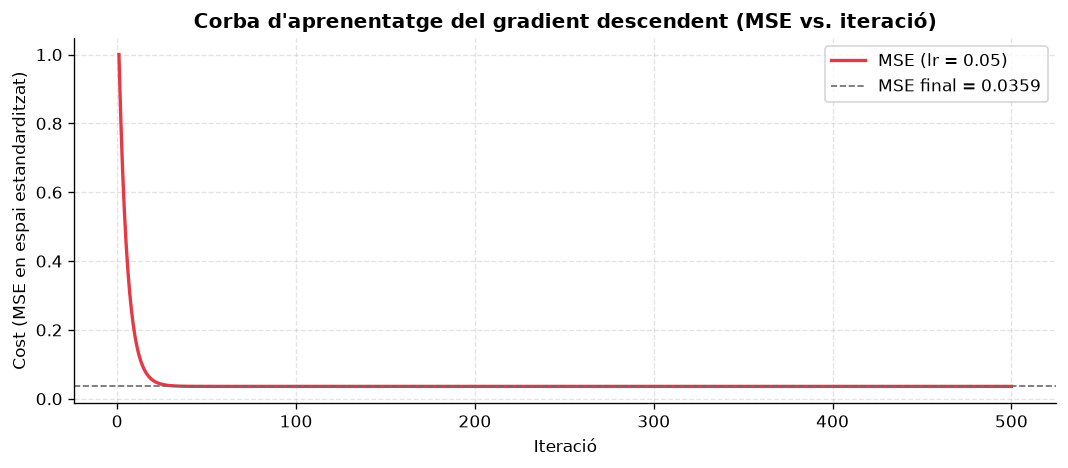

In [9]:
# 🔧 4.5 · Visualitza la corba d'aprenentatge (MSE vs. iteració)
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(range(1, n_iter + 1), history, color="#e63946", linewidth=2, label=f"MSE (lr = {lr})")
ax.axhline(history[-1], color="dimgray", linestyle="--", linewidth=1, label=f"MSE final = {history[-1]:.4f}")

ax.set_title("Corba d'aprenentatge del gradient descendent (MSE vs. iteració)", fontsize=12, fontweight="bold")
ax.set_xlabel("Iteració")
ax.set_ylabel("Cost (MSE en espai estandarditzat)")
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


In [10]:
# 🔧 4.6 · Converteix els paràmetres de l'espai normalitzat a l'original
m_orig = m_norm * d_std / t_std
b_orig = d_std * b_norm + d_mean - m_orig * t_mean

print(f"Model (escala original):")
print(f"  diferència = {m_orig:.0f} × any  +  {b_orig:.0f}")
print(f"  Pendent: {m_orig:.0f} persones/any")


Model (escala original):
  diferència = -29264 × any  +  59817930
  Pendent: -29264 persones/any


In [11]:
# ✅ Validació: compara el resultat de GD amb np.polyfit
coefs_ref = np.polyfit(anys, difs, 1)

print(f"{'M\u00e8tode':<20} {'m (pendent)':>14} {'b (intercept)':>15}")
print("-" * 52)
print(f"{'Gradient descendent':<20} {m_orig:>14.1f} {b_orig:>15.0f}")
print(f"{'np.polyfit (ref.)':<20} {coefs_ref[0]:>14.1f} {coefs_ref[1]:>15.0f}")
print()
err_m = abs(m_orig - coefs_ref[0]) / abs(coefs_ref[0]) * 100
err_b = abs(b_orig - coefs_ref[1]) / abs(coefs_ref[1]) * 100
print(f"Error relatiu:  m = {err_m:.2f}%   b = {err_b:.2f}%")
print("Si l'error < 1%, el gradient descendent ha convergit correctament.")

Mètode                  m (pendent)   b (intercept)
----------------------------------------------------
Gradient descendent        -29264.3        59817930
np.polyfit (ref.)          -29264.3        59817930

Error relatiu:  m = 0.00%   b = 0.00%
Si l'error < 1%, el gradient descendent ha convergit correctament.


---
## Part 5 — Punt de creuament

La diferència comença positiva i, si la tendència és lineal, arribarà a zero
en algun any futur. Aquell any és la resposta a la nostra pregunta.

Resol analíticament:

$$m_{\text{orig}} \cdot t^{*} + b_{\text{orig}} = 0
\quad \Longrightarrow \quad
t^{*} = -\frac{b_{\text{orig}}}{m_{\text{orig}}}$$

In [12]:
# 🔧 Calcula l'any de creuament usant m_orig i b_orig
any_creuament = -b_orig / m_orig

print(f"Any de creuament: {any_creuament:.2f}")
print(f"→ Cap a l'any {int(np.ceil(any_creuament))}, la 'Resta del món' superarà BCN+Cat+Esp")


Any de creuament: 2044.06
→ Cap a l'any 2045, la 'Resta del món' superarà BCN+Cat+Esp


---
## Part 6 — Visualització final amb projecció

Crea un gràfic que mostri:
- Els punts de la **diferència observada** (1997–2026).
- La **recta del model** extrapolada fins al punt de creuament (línia discontínua).
- La **línia zero** i el **punt de creuament** anotat.

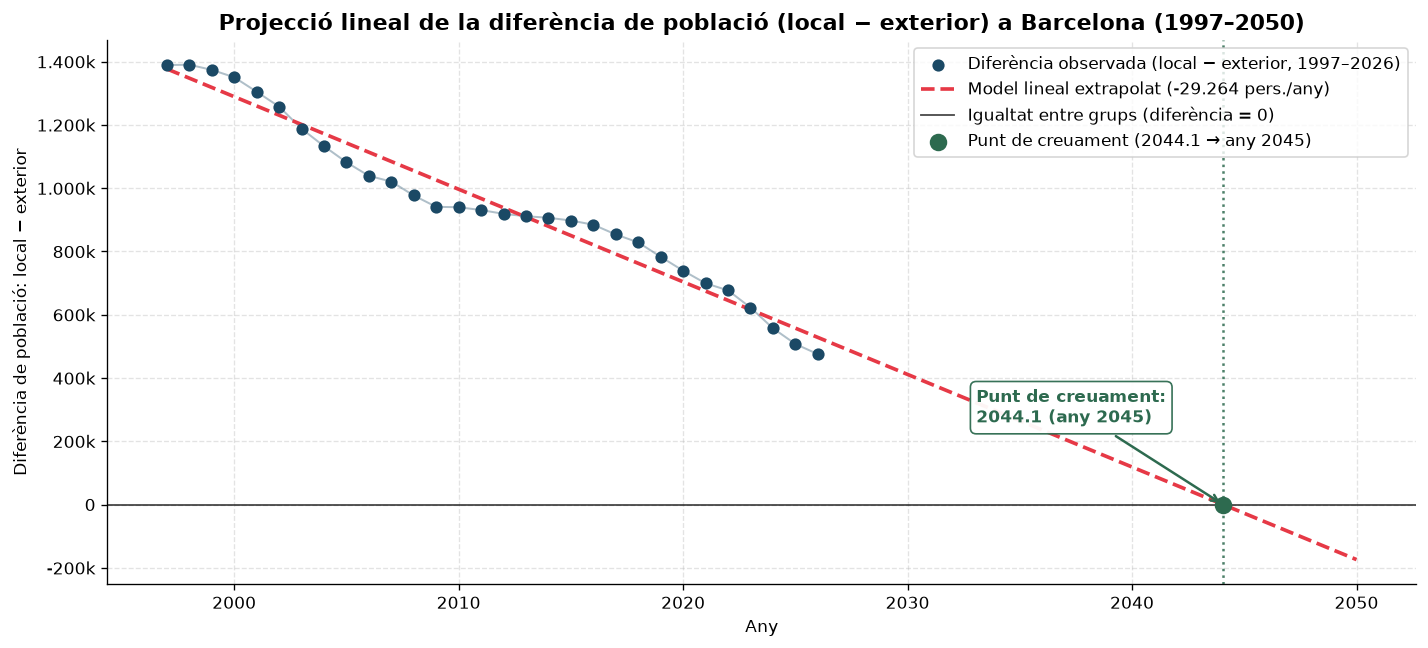

In [13]:
# 🔧 Gràfic de la diferència + model + projecció
model_orig = lambda t: m_orig * t + b_orig

anys_proj = np.arange(1997, int(np.ceil(any_creuament)) + 6, dtype=float)
difs_proj = model_orig(anys_proj)

fig, ax = plt.subplots(figsize=(12, 5.5))

# Punts de la diferència observada (1997–2026)
ax.scatter(
    anys,
    difs,
    color="#1b4965",
    s=40,
    zorder=4,
    label="Diferència observada (local − exterior, 1997–2026)",
)
ax.plot(anys, difs, color="#1b4965", alpha=0.35, linewidth=1.2)

# Recta del model extrapolada
ax.plot(
    anys_proj,
    difs_proj,
    color="#e63946",
    linestyle="--",
    linewidth=2.2,
    label=f"Model lineal extrapolat ({m_orig:,.0f} pers./any)".replace(",", "."),
)

# Línia zero i punt de creuament
ax.axhline(0, color="black", linestyle="-", linewidth=1.1, alpha=0.7, label="Igualtat entre grups (diferència = 0)")
ax.axvline(any_creuament, color="#2d6a4f", linestyle=":", linewidth=1.5, alpha=0.85)
ax.scatter(
    [any_creuament],
    [0],
    color="#2d6a4f",
    s=90,
    zorder=6,
    label=f"Punt de creuament ({any_creuament:.1f} → any {int(np.ceil(any_creuament))})",
)

ax.annotate(
    f"Punt de creuament:\n{any_creuament:.1f} (any {int(np.ceil(any_creuament))})",
    xy=(any_creuament, 0),
    xytext=(any_creuament - 11, 260000),
    arrowprops=dict(arrowstyle="->", color="#2d6a4f", lw=1.5),
    fontsize=10,
    fontweight="bold",
    color="#2d6a4f",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#2d6a4f", alpha=0.95),
)

ax.set_title("Projecció lineal de la diferència de població (local − exterior) a Barcelona (1997–2050)", fontsize=13, fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Diferència de població: local − exterior")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x/1000):,}k".replace(",", ".") if x != 0 else "0"))
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("grafic_projeccio.png", bbox_inches="tight", dpi=150)
plt.show()


---
## Part 7 — Interpretació crítica

Respon les preguntes següents en les cel·les Markdown (3-5 frases per apartat).

**a) Quan superarà la «Resta del món» els grups locals? Quin és el grau de
confiança d'aquesta predicció?**

Segons el model lineal entrenat sobre el període 1997–2026 (amb un pendent de $-29.264$ persones/any), la diferència entre el grup local i l'exterior arribarà a zero a principis de **2044** ($t^* = 2044,06$), de manera que en el padró de l'any **2045** la població nascuda a l'estranger ja hauria superat la nascuda a Espanya. Tot i que l'ajust lineal captura bé la tendència mitjana de les darreres tres dècades, el **grau de confiança d'una extrapolació a gairebé 20 anys vista és moderat-baix**. Els fluxos migratoris i la demografia urbana depenen de factors altament volàtils —com el cicle econòmic, la capacitat del parc d'habitatge de Barcelona, els preus del lloguer i les polítiques d'estrangeria— que difícilment es mantindran constants fins al 2045. Per tant, aquesta data s'ha d'interpretar com una projecció tendencial condicional («si es manté el ritme mitjà 1997–2026») i no com una predicció determinista.


**b) Quina influència té la tria de `lr` (learning rate) i `n_iter` sobre
el resultat? Què passa si `lr` és massa gran? I massa petit?**

La taxa d'aprenentatge (`lr`, $\alpha$) determina la mida del pas en cada actualització dels paràmetres i `n_iter` fixa quants passos es fan; conjuntament determinen si l'algorisme arriba al mínim de la funció de cost MSE. Si `lr` és **massa gran** (en aquest problema estandarditzat, $\alpha \ge 1,0$), els passos sobrepassen el mínim de la paràbola de cost i l'algorisme oscil·la brusca i indefinidament o divergeix cap a infinit ($J \to \infty$). En canvi, si `lr` és **massa petit** (per exemple, $\alpha = 0,0001$) i `n_iter` no s'incrementa proporcionalment, el descens és extremadament lent i l'entrenament s'atura abans de convergir, deixant $m$ i $b$ lluny dels valors òptims (subajustament) i produint una predicció esbiaixada de l'any de creuament. Amb les variables estandarditzades, una combinació equilibrada com `lr = 0.05` i `n_iter = 500` aconsegueix una convergència exacta amb un error relatiu del $0,00\%$ respecte a `np.polyfit`.


**c) Un model lineal assumeix un ritme de canvi constant. Observes algun
període on la tendència va ser significativament diferent (crisi 2008,
pandèmia 2020)? Com afecta això a la fiabilitat de la predicció?**

Sí, al gràfic dels punts observats s'aprecien clarament tres règims ben diferenciats que s'allunyen d'un ritme lineal constant: una caiguda molt ràpida de la diferència durant el boom migratori (2000–2008), un **aplanament gairebé total entre el 2009 i el 2015** arran de la crisi financera (quan es va frenar l'arribada d'immigrants i fins i tot es van produir retorns), una pausa puntual durant la **pandèmia de la COVID-19 (2020–2021)** i una forta acceleració entre el 2022 i el 2025. Aquests canvis de pendent demostren que l'evolució demogràfica és cíclica i sensible als xocs macroeconòmics. Això redueix la fiabilitat de la predicció puntual: si en el futur predomina el ritme accelerat postpandèmia (2022–2026, d'uns $-50.000$ hab./any), el creuament s'avançaria a la segona meitat de la dècada del 2030, mentre que una nova desacceleració o el límit de capacitat residencial de Barcelona el retardaria força més enllà del 2045.
